# Project 1: final results

**Team Saber: Kevin Yang (ky2738)**  
Code: [https://github.com/Solvement/26-Deep-Learning-Project-1-Kaggle](https://github.com/Solvement/26-Deep-Learning-Project-1-Kaggle)

This notebook prints the final model's parameter count and test accuracy and plots the measured learning curves and Kaggle scores. It reads only scalar evidence committed under `docs/`.

In [1]:
from pathlib import Path
import json, sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'model.py').is_file())
sys.path.insert(0, str(ROOT))
scores = json.loads((ROOT / 'docs/final-kaggle-scores.json').read_text())['submissions']
curves = json.loads((ROOT / 'docs/final-curves.json').read_text())
print(len(scores), 'official Kaggle submissions loaded')

16 official Kaggle submissions loaded


## 1. Final architecture and parameter budget
The final student is a pre-activation WideResNet-22-4: 3x3 stem (16 ch), three stages of three residual blocks (64/128/256 channels, stride 1/2/2), 1x1 projection shortcuts, global average pooling, linear head.

In [2]:
import torch
from model import build_model, count_parameters
model = build_model(depth=22, widen_factor=4, dropout=0.0, num_classes=10)
n_total, n_train = count_parameters(model), count_parameters(model, trainable_only=True)
assert n_total <= 5_000_000 and n_train == n_total
print(f'Trainable parameters: {n_train:,}  (limit 5,000,000)')
print('Output shape:', tuple(model(torch.zeros(2, 3, 32, 32)).shape))
for name, child in model.named_children():
    print(f'  {name:10s} {count_parameters(child):>10,}')

Trainable parameters: 4,298,970  (limit 5,000,000)
Output shape: (2, 10)
  stem              432
  stage1        195,232
  stage2        820,608
  stage3      3,279,616
  final_bn          512
  final_relu          0
  pool                0
  classifier      2,570


## 2. Knowledge distillation vs. the same recipe without it
Both runs: WRN-22-4, 40,000 training images, 160 epochs, seed 2026, SGD + cosine, Cutout + MixUp. The KD run adds the soft targets of four scratch-trained teachers (T=4, alpha=0.9). Accuracy is on the 5,000-image development split.

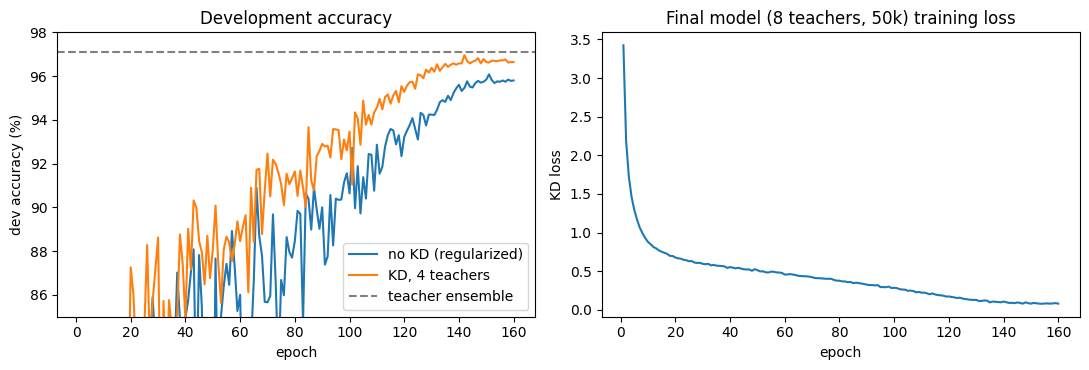

No KD : final dev 95.80%  (best 96.08%)
KD    : final dev 96.64%  flip-TTA 96.96%
Teacher ensemble dev: 97.08%


In [3]:
import matplotlib.pyplot as plt
r, k = curves['no_kd_regularized_40k'], curves['kd_4teachers_40k']
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(r['epoch'], [100*v for v in r['dev']], label='no KD (regularized)')
ax[0].plot(k['epoch'], [100*v for v in k['dev']], label='KD, 4 teachers')
ax[0].axhline(100*k['teacher_ensemble_dev'], ls='--', c='gray', label='teacher ensemble')
ax[0].set(ylim=(85, 98), xlabel='epoch', ylabel='dev accuracy (%)', title='Development accuracy'); ax[0].legend()
k8 = curves['kd_8teachers_50k']
ax[1].plot(k8['epoch'], k8['loss']); ax[1].set(xlabel='epoch', ylabel='KD loss', title='Final model (8 teachers, 50k) training loss')
plt.tight_layout(); plt.show()
print(f"No KD : final dev {100*r['dev'][-1]:.2f}%  (best {100*max(r['dev']):.2f}%)")
print(f"KD    : final dev {100*k['dev'][-1]:.2f}%  flip-TTA {100*k['dev_flip'][-1]:.2f}%")
print(f"Teacher ensemble dev: {100*k['teacher_ensemble_dev']:.2f}%")

## 3. All official Kaggle scores (public and private halves, 1,000 images each)

entry                             arch        train   ep  public  private
baseline                          WRN-16-2    40000  160   83.5%    80.9%
architecture                      WRN-22-4    40000  160   85.4%    83.3%
regularized                       WRN-22-4    40000  160   87.4%    84.5%
final_full (pre-declared primary) WRN-22-4    50000  160   87.1%    86.5%
robust_full                       WRN-22-4    50000  300   86.2%    84.2%
WRN34-3/160                       WRN-34-3    40000  160   86.9%    84.4%
ResizeMix                         WRN-22-4    40000  160   87.5%    84.2%
WRN34-3/300                       WRN-34-3    40000  300   87.8%    84.7%
SAM                               WRN-22-4    40000  160   87.1%    85.8%
TrivialAugment                    WRN-34-3    40000  160   86.7%    85.7%
WRN34-3 full-data refit           WRN-34-3    50000  160   88.0%    84.9%
SAM full-data refit               WRN-22-4    50000  160   88.1%    85.6%
TrivialAugment full-data refit    WRN-

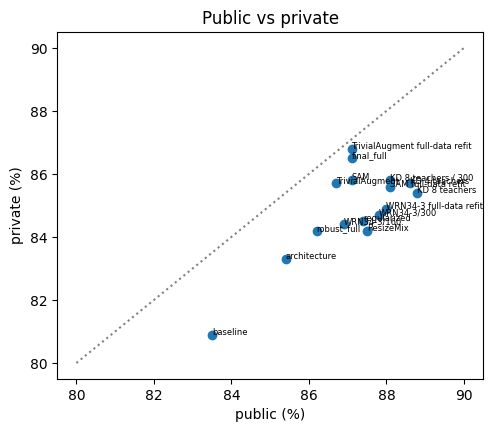

corr(public, private) all=0.75; after the first three entries=0.13
binomial SE of one 1,000-image half at 86%: 1.1 pp


In [4]:
import numpy as np
print(f"{'entry':34s}{'arch':10s}{'train':>7s}{'ep':>5s}{'public':>8s}{'private':>9s}")
for s in scores:
    print(f"{s['label']:34s}{s['arch']:10s}{s['train_images']:>7d}{s['epochs']:>5d}{100*s['public']:>7.1f}%{100*s['private']:>8.1f}%")
pub, priv = np.array([s['public'] for s in scores]), np.array([s['private'] for s in scores])
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.scatter(100*pub, 100*priv)
for s in scores: ax.annotate(s['label'].split(' (')[0], (100*s['public'], 100*s['private']), fontsize=6)
ax.plot([80, 90], [80, 90], ls=':', c='gray'); ax.set(xlabel='public (%)', ylabel='private (%)', title='Public vs private')
plt.show()
late = slice(3, None)
print(f'corr(public, private) all={np.corrcoef(pub, priv)[0,1]:.2f}; after the first three entries={np.corrcoef(pub[late], priv[late])[0,1]:.2f}')
print(f'binomial SE of one 1,000-image half at 86%: {100*np.sqrt(.86*.14/1000):.1f} pp')

## 4. Final test accuracy

In [5]:
final = next(s for s in scores if s['label'] == 'KD 8 teachers')
best_priv = max(scores, key=lambda s: s['private'])
print(f"FINAL MODEL: {final['arch']} student, {final['method']}, {final['train_images']:,} images")
print(f"Number of parameters: {final['params']:,}")
print(f"Final test accuracy: public {100*final['public']:.1f}%, private {100*final['private']:.1f}%  (Kaggle ref {final['ref']})")
print(f"Best private score among all entries: {100*best_priv['private']:.1f}% ({best_priv['label']}, {best_priv['params']:,} params)")

FINAL MODEL: WRN-22-4 student, ensemble distillation, 8 scratch teachers, 50,000 images
Number of parameters: 4,298,970
Final test accuracy: public 88.8%, private 85.4%  (Kaggle ref 58010328)
Best private score among all entries: 86.8% (TrivialAugment full-data refit, 4,166,298 params)


## Reproduction
```
python prepare_data.py            # official Kaggle files only
python train.py --config configs/wrn_final.json --output-dir results/final_full   # one teacher / no-KD baseline
python research/train_kd_ensemble.py --teachers full50k_8 --output-dir results/research/kd_full50k8_s2026_v1
python research/predict_kd.py --checkpoint results/research/kd_full50k8_s2026_v1/final_model.pt --output-dir out/
```
See README for the teacher runs. Data, checkpoints and prediction files are not stored in Git.